# Principal Component Analysis (PCA)

PCA is a method for reducing the number of columns while retaining as much information as possible.

**Outcomes**:
- Explain the basics of the PCA algorithm
- Define variance, principal components, and orthogonal
- Explain why we want to reduce the number of columns in a dataset
- Explain why we may add the PCs back onto an original dataset
- Explain how graphing the PCs can help us understand the data
- Apply PCA for dimensionality reduction

**Links**:
- [template census data](census.csv) and [PCA example](census_pca_example.ipynb)
- [YouTube Video](https://www.youtube.com/watch?v=FD4DeN81ODY)

## Roadmap

Use this map to follow the code blocks below. Steps 1a–1c all happen in the Step 1 code block, and Steps 3a and 3b both happen in the Step 3 code block.

![PCA roadmap](pca-roadmap.svg)

## PCA Algorithm

Principal Component Analysis (PCA) is a technique for:

* *Reducing dimensionality* (many features → fewer features),
* While *preserving as much variance as possible*,
* By creating new, *uncorrelated* features called *principal components*.

Each principal component is:

* A linear combination of the original features.
* Orthogonal (perpendicular) to the others.
* Ordered so that:

  * PC1 explains the most variance,
  * PC2 explains the second most variance,
  * etc.

Key Concepts:

- Variance measures how spread out the values of a feature are around their mean. PCA treats variance as information: a column where every row has nearly the same value tells us little about how the rows differ.
- A dimension is one feature (column). Reducing the number of columns is useful because:
    - Fewer columns are easier to graph and understand. We cannot plot 8 features at once, but we can plot 2 principal components.
    - Many features are redundant. When features are highly correlated, they carry mostly the same information, and a few components can replace them.
    - Other models can run faster, and with less overfitting, on a few uncorrelated inputs than on many correlated ones.
- PCA is an unsupervised method. There is no dependent variable and no train/test split.
- Scale the features first. PCA looks for variance, so a feature with large units (price in dollars) would dominate a feature with small units (number of cylinders). Standardizing gives every feature a mean of 0 and a variance of 1.

Problems:

- Principal components are harder to interpret than the original features, because each one is a mix of all of them.
- Keeping only some of the components throws away the remaining variance, so some information is lost.

### Step 1: Scale the data and fit PCA

We start with 8 numeric features for 20 cars, standardize them, and ask PCA for 2 principal components.

The explained variance ratio printed at the end shows the share of the total variance captured by each component. Here PC1 captures about 96% and PC2 about 2.5%, so two columns keep nearly 99% of the information that was in the original eight. This works so well because the car features are highly correlated: bigger engines come with more power, weight, and price, and lower mpg.

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Create a dataset of predefined car samples
df = pd.DataFrame({
    'engine_displacement': [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 1.8, 2.2, 2.8, 3.5, 4.2, 5.5],
    'num_cylinders': [3, 4, 4, 4, 5, 6, 6, 8, 8, 8, 10, 10, 12, 12, 4, 4, 6, 6, 8, 8],
    'engine_power': [120, 160, 200, 250, 280, 320, 380, 450, 520, 580, 600, 640, 650, 720, 140, 180, 300, 350, 520, 600],
    'price': [25000, 32000, 38000, 45000, 52000, 60000, 72000, 85000, 95000, 110000, 125000, 135000, 145000, 150000, 28000, 35000, 55000, 65000, 90000, 120000],
    'weight': [2500, 2700, 2900, 3100, 3300, 3600, 3900, 4200, 4500, 4700, 4900, 5000, 5100, 5200, 2600, 2800, 3200, 3500, 4300, 4600],
    'mpg': [38, 32, 28, 25, 22, 20, 18, 16, 14, 12, 11, 10, 9, 8, 35, 30, 21, 19, 15, 12],
    'year': [2023, 2023, 2023, 2022, 2022, 2022, 2021, 2021, 2020, 2020, 2019, 2019, 2018, 2018, 2023, 2023, 2022, 2022, 2021, 2020],
    'acceleration': [10.5, 8.2, 7.1, 6.5, 6.0, 5.5, 5.0, 4.5, 4.2, 3.9, 3.7, 3.5, 3.3, 3.0, 9.8, 8.0, 6.8, 6.2, 4.8, 4.0]
})

# Add car type classification
df['car_type'] = df.apply(
    lambda row: 'Sports Car' if (row['engine_power'] >= 400 or row['acceleration'] < 5.0) else 'Economy Car',
    axis=1
)

# PCA works best when features are centered; standardization is often used when units differ.
X = df[['engine_displacement', 'num_cylinders', 'engine_power', 'price', 'weight', 'mpg', 'year', 'acceleration']].values  # shape: (20, 8)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) 
# `X_scaled` has mean ~0 and variance ~1 in each column.

# Fit PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Principal components (directions):")
print(pca.components_)

# Share of the total variance that each principal component explains
print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

Principal components (directions):
[[ 0.35663352  0.35106612  0.35776287  0.35699674  0.35874068 -0.35013588
  -0.35279264 -0.34405162]
 [ 0.13807797  0.35411536  0.01102768  0.24256939 -0.01602305  0.49075458
  -0.38000873  0.64114884]]

Explained variance ratio:
[0.96151962 0.02508788]
Total: 0.9866075022459072


### Step 2: Interpret the components

The scores are each car's position on PC1 and PC2. They are found by projecting each car's standardized values onto the components.

The loadings show how strongly each original feature contributes to each component. The sign shows the direction.

- PC1 has loadings of about 0.35 on every feature: positive for displacement, cylinders, power, price, and weight, and negative for mpg, year, and acceleration time. A car with a high PC1 score is a big, powerful, expensive car with low mpg. PC1 is an overall "size and power" measure.
- PC2 is driven mostly by acceleration time and mpg, but it explains only about 2.5% of the variance.

In [2]:
# Show the principal component scores: each car's position on PC1 and PC2
print("\nPrincipal component scores (projections):")
print(X_pca)

# Display loadings - how each variable aligns with each component
feature_names = ['engine_displacement', 'num_cylinders', 'engine_power', 'price', 'weight', 'mpg', 'year', 'acceleration']
loadings_df = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=feature_names
)

print("\n\nLoadings - Alignment of Variables with Principal Components:")
print("(Shows how strongly each variable contributes to each PC)")
print(loadings_df)

print("\n\nVariable Contributions (sorted by absolute value):")
print("\nPC1 - Top contributors:")
print(loadings_df['PC1'].abs().sort_values(ascending=False))
print("\nPC2 - Top contributors:")
print(loadings_df['PC2'].abs().sort_values(ascending=False))


Principal component scores (projections):
[[-4.47305525  1.01239304]
 [-3.41510905  0.18644614]
 [-2.77413926 -0.30144973]
 [-2.01184745 -0.34278791]
 [-1.38674124 -0.45324969]
 [-0.7335913  -0.50296825]
 [ 0.07604103 -0.42887747]
 [ 0.96266473 -0.31329746]
 [ 1.74070809 -0.18980161]
 [ 2.28919508 -0.26651954]
 [ 3.18508469  0.23903071]
 [ 3.55484559  0.2190217 ]
 [ 4.34716719  0.6955037 ]
 [ 4.74551173  0.61650451]
 [-3.94681628  0.80369696]
 [-3.16107063  0.04555603]
 [-1.45018632 -0.16103636]
 [-0.83915274 -0.34751079]
 [ 1.02302003 -0.30238363]
 [ 2.26747136 -0.20827034]]


Loadings - Alignment of Variables with Principal Components:
(Shows how strongly each variable contributes to each PC)
                          PC1       PC2
engine_displacement  0.356634  0.138078
num_cylinders        0.351066  0.354115
engine_power         0.357763  0.011028
price                0.356997  0.242569
weight               0.358741 -0.016023
mpg                 -0.350136  0.490755
year           

### Step 3: Add PCA results back to a DataFrame

We can add the PCs back onto the original dataset as new columns. This lets us use them alongside the original columns for further analysis: graphing, comparing against a known category, or as inputs to another model.

Graphing PC1 against PC2 shows all 8 features in a single two-dimensional plot. In the plot below, the sports cars sit on the right (high PC1) and the economy cars on the left (low PC1). PCA was never told the car type, yet PC1 separates the two groups.

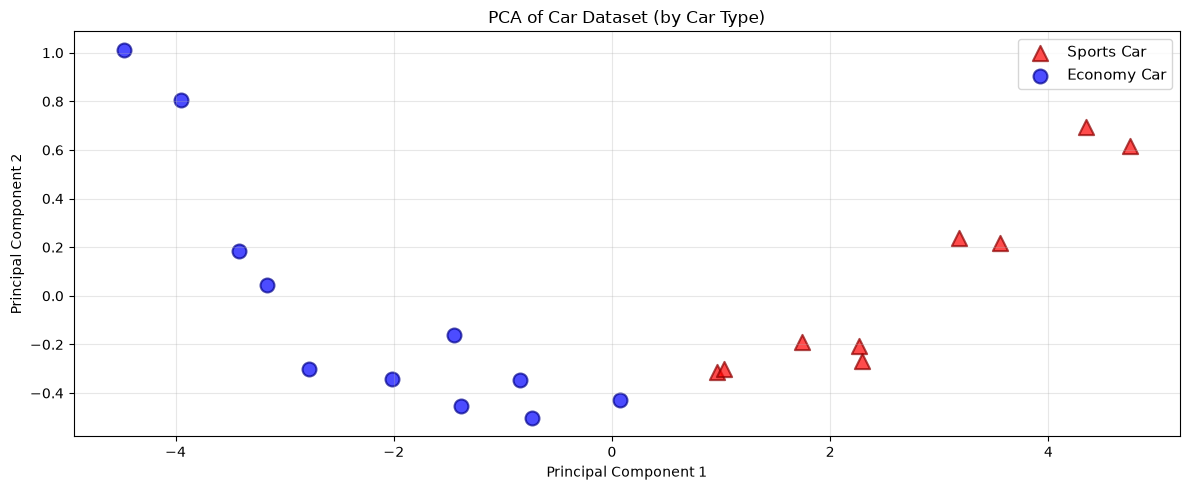

In [3]:
df_pca = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

df_with_pca = pd.concat([df.reset_index(drop=True), df_pca], axis=1)

import matplotlib.pyplot as plt

# Plot PCA-transformed data colored and shaped by car type
plt.figure(figsize=(12, 5))

# Separate data by car type
sports_cars = df_with_pca[df_with_pca['car_type'] == 'Sports Car']
economy_cars = df_with_pca[df_with_pca['car_type'] == 'Economy Car']

# Plot each group with different color and marker shape
plt.scatter(sports_cars['PC1'], sports_cars['PC2'], c='red', marker='^', s=120, alpha=0.7, label='Sports Car', edgecolors='darkred', linewidth=1.5)
plt.scatter(economy_cars['PC1'], economy_cars['PC2'], c='blue', marker='o', s=100, alpha=0.7, label='Economy Car', edgecolors='darkblue', linewidth=1.5)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Car Dataset (by Car Type)')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Example PCA Process

This image shows the PCA training process on a dataset with three features reduced to two principal components.

![PCA Process](pca_training.gif)

## Key Terms

- **Principal Component Analysis (PCA)**: A method for reducing the number of columns in a dataset while retaining as much information as possible
- **Dimensionality reduction**: Turning many features into fewer features
- **Dimension**: One feature (column) in a dataset
- **Variance**: How spread out the values of a feature are around their mean; in PCA, variance is treated as information
- **Principal component (PC)**: A new feature that PCA creates as a linear combination of the original features
- **Linear combination**: A weighted sum of features, such as 0.36 × weight + 0.36 × price − 0.35 × mpg
- **Orthogonal**: Perpendicular; each principal component points in a direction at a right angle to the others
- **Uncorrelated**: Having a correlation of zero; principal components are uncorrelated with each other
- **PC1**: The first principal component, the direction that explains the most variance in the data
- **PC2**: The second principal component, which explains the most remaining variance while staying orthogonal to PC1
- **Explained variance ratio**: The share of the total variance captured by each principal component (`explained_variance_ratio_`)
- **Loading**: The weight showing how strongly an original feature contributes to a principal component (`components_`)
- **Principal component score**: A row's value on a principal component, found by projecting the row onto that component
- **Standardization (PCA)**: Rescaling every feature to a mean of 0 and a variance of 1 before PCA so that features with large units do not dominate
- **Number of components**: How many principal components to keep, set with `n_components`
- **Redundant features**: Features that are highly correlated and so carry mostly the same information
- **Information loss**: The variance that is thrown away when only some of the principal components are kept


## Practice Questions

1. What is the main purpose of PCA?
   - To reduce the number of columns while retaining as much information as possible
   - To predict a dependent variable from several inputs
   - To group rows into K clusters
   - To fill in missing values
1. What does "dimensionality reduction" mean?
   - Turning many features into fewer features
   - Removing rows from the dataset
   - Rounding numbers to fewer decimal places
   - Splitting the data into training and test sets
1. What does PCA try to preserve as it reduces the number of features?
   - As much variance as possible
   - The original column names
   - The number of rows in each cluster
   - The p-value of each feature
1. What is variance?
   - How spread out the values of a feature are around their mean
   - The average value of a feature
   - The number of features in a dataset
   - The correlation between two features
1. What is a principal component?
   - A new feature made from a linear combination of the original features
   - The original feature with the largest values
   - A cluster of similar rows
   - The dependent variable in the model
1. What does it mean that principal components are orthogonal?
   - They are perpendicular to each other, so they are uncorrelated
   - They are identical to each other
   - They each use only one original feature
   - They are sorted alphabetically
1. How are the principal components ordered?
   - PC1 explains the most variance, PC2 the second most, and so on
   - Alphabetically by the name of the largest feature
   - In the same order as the original columns
   - Randomly each time the model runs
1. What is the correlation between PC1 and PC2?
   - Zero, because principal components are uncorrelated
   - 1, because they come from the same data
   - -1, because they point in opposite directions
   - It depends on the units of the original features
1. Why do we standardize the features before running PCA?
   - Otherwise features with large units, such as price, would dominate the variance
   - PCA cannot read numbers larger than 1
   - Standardizing removes the correlated features
   - Standardizing chooses the number of components
1. Our car dataset has 8 numeric features and we use `PCA(n_components=2)`. How many columns does `X_pca` have?
   - 2
   - 8
   - 10
   - 16
1. In our example, PC1 explains about 96% of the variance and PC2 about 2.5%. What does this tell you?
   - Two components keep nearly 99% of the information that was in the 8 features
   - The model is 96% accurate
   - 96% of the cars are sports cars
   - PC2 is more important than PC1
1. Why can one component capture so much of the variance in the car data?
   - The features are highly correlated: bigger engines come with more power, weight, and price, and lower mpg
   - The dataset only has 20 rows
   - The features were standardized
   - PCA always puts 96% of the variance in PC1
1. What does a loading tell you?
   - How strongly an original feature contributes to a principal component
   - How many rows are in the dataset
   - The share of variance explained by a component
   - The predicted value for a row
1. In our example, `mpg` has a PC1 loading of about -0.35 while `weight` has about +0.36. What does this mean?
   - Cars with a high PC1 score tend to be heavy and have low mpg
   - Cars with a high PC1 score tend to be light and have high mpg
   - mpg is not used in PC1
   - mpg and weight are uncorrelated
1. Why would we want to reduce the number of columns in a dataset?
   - Fewer columns are easier to graph and understand, and they remove redundant, correlated features
   - Fewer columns always raise the accuracy of a model
   - Datasets cannot have more than two columns
   - It removes rows with missing values
1. Why might we add the PCs back onto the original dataset?
   - So we can use them alongside the original columns for further analysis, such as graphing or as inputs to another model
   - So the original columns can be deleted automatically
   - Because PCA cannot run without them
   - To increase the number of rows
1. How does graphing PC1 against PC2 help us understand the data?
   - It shows many features in a single two-dimensional plot, revealing groups and patterns
   - It shows the p-value of each feature
   - It shows which rows have missing values
   - It replaces the need to standardize the data
1. In the PCA plot, sports cars sit on the right and economy cars on the left. What does this show?
   - PC1 separates the two types, even though PCA was never given the car type
   - PCA was trained to predict the car type
   - PC2 separates the two types
   - The car types were assigned at random
1. What is a downside of using principal components in place of the original features?
   - They are harder to interpret, because each one is a mix of all the original features
   - They are always highly correlated with each other
   - They cannot be graphed
   - They require a dependent variable
1. Is PCA supervised or unsupervised?
   - Unsupervised, because it uses no dependent variable
   - Supervised, because it predicts the car type
   - Supervised, because it requires a train/test split
   - Neither, because it does not use data